# Flower Classification Project

Your task is to **classify photos of flowers as roses, sunflowers or tulips**, with only 100 photos per kind of flower to learn from, using **transfer learning**.

# The Business Problem

A garden centre runs a website where customers upload a photo of a flower from their garden and receive a care guide for it: when to water, when to cut it back, which pests to watch for. At the moment, a member of staff looks at every photo and chooses the right guide by hand. The garden centre starts with its three most requested guides, **roses, sunflowers and tulips**, and wants a model that chooses the guide automatically from the photo.

Your model answers this question: given a photo, which of the three flowers does it show? A wrong answer sends a customer the wrong care guide, so at the end you look at **which photos the model gets wrong**, so that the garden centre knows when to trust it and when a member of staff should check the answer.

The model can only answer with one of the three flowers. A photo of a daisy would still receive one of the three labels, so the website has to make clear which flowers the service covers.

# Data Description

The data ships with this repository in the folder `data/`: **390 colour photos**, one JPEG file per photo, sorted into one folder per kind of flower. The name of the folder is the label of the photo.

| Folder | Photos | Description |
| :-- | :-- | :-- |
| `data/train/rose` | 100 | roses, for training |
| `data/train/sunflower` | 100 | sunflowers, for training |
| `data/train/tulip` | 100 | tulips, for training |
| `data/validation/rose` | 20 | roses, for choosing the model |
| `data/validation/sunflower` | 20 | sunflowers, for choosing the model |
| `data/validation/tulip` | 20 | tulips, for choosing the model |
| `data/test/rose` | 10 | roses, **the test set** |
| `data/test/sunflower` | 10 | sunflowers, **the test set** |
| `data/test/tulip` | 10 | tulips, **the test set** |

The photos have different sizes, from 159 to 640 pixels wide, and show the flowers in very different ways: a single flower close up, a whole field, a bunch in a vase, sometimes with people or buildings in the picture.

The photos are part of the [TensorFlow flower photos](https://www.tensorflow.org/datasets/catalog/tf_flowers) collection and were taken from Flickr. Every photo is licensed under [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/); its photographer is listed in `data/LICENSE.txt`.

## Task

1. **Get the data.** Display a few photos of every class from `data/train`.
2. **Load the training and the validation images.** Load `data/train` and `data/validation` with `keras.utils.image_dataset_from_directory`, with one `image_size` that you use for every model, for example `(160, 160)`. Shuffle the training images with a fixed `seed`; keep the validation images in their order with `shuffle=False`. Do not load `data/test` until step 6.
3. **Explore the training set.** Display a grid of training photos with their labels. What makes the three flowers look different: colour, shape, the background?
4. **Repurpose a pretrained network.** Use `MobileNetV2` from `keras.applications` as the pretrained network and repurpose it to classify the three flowers. Plot its learning curves: does it overfit?

> [!IMPORTANT]
> **Every image has to be prepared in exactly the same way**: the same `image_size`, the same `preprocess_input` of the base, and the same frozen base, for the training, the validation and later the test images.

5. **If needed, improve the model with data augmentation**, and compare the validation accuracy with step 4. Choose your best model by its validation accuracy. **Save every model to a file** with `model.save`, for example `models/dense_head.keras`, so that you can load all of them in step 6 with `keras.models.load_model`, even after restarting the notebook.
6. **Evaluate all models on the test set at the very end.** Load your saved models, and load `data/test` with the same `image_size` and with `shuffle=False`. Then:
    1. Collect the **validation and test accuracy of every model** in **one table**. Is the validation accuracy of your chosen model a fair estimate of its test accuracy? The test set has only 30 photos, so **one photo changes the test accuracy by 3.3 percentage points**.
    2. **Plot the confusion matrix** of your best model on the test set. Which flowers does it confuse?
    3. **Display every misclassified test photo**, with its true and predicted label. What do these photos have in common?
7. **Try your model in an app.** The repository contains a small [Streamlit](https://docs.streamlit.io/) app, `app.py`, that loads a model from `models/` and classifies a photo that you upload. Start it in a terminal in the repository folder with `uv run streamlit run app.py`, choose your best model, and upload a few flower photos of your own. Does the model get them right? The app works with models that take the raw photos and include their preprocessing, such as `preprocess_input`, as layers.

In [1]:
# Import the libraries you need for this project
from pathlib import Path

import keras
import keras_tuner as kt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras.applications import mobilenet_v2

from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# Load Images

In [2]:
# Loading the images

IMAGE_SIZE = (160, 160)

FLOWERS = Path("./data")

SEED = 42

def load_images(split, shuffle):
    return keras.utils.image_dataset_from_directory(
       FLOWERS / split, image_size=IMAGE_SIZE, batch_size=32, label_mode="int", shuffle=shuffle, seed=SEED
    )

train_ds = load_images("train", shuffle=True)
valid_ds = load_images("validation", shuffle=False)

class_names = train_ds.class_names

print("Classes:", class_names)

Found 300 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Classes: ['rose', 'sunflower', 'tulip']


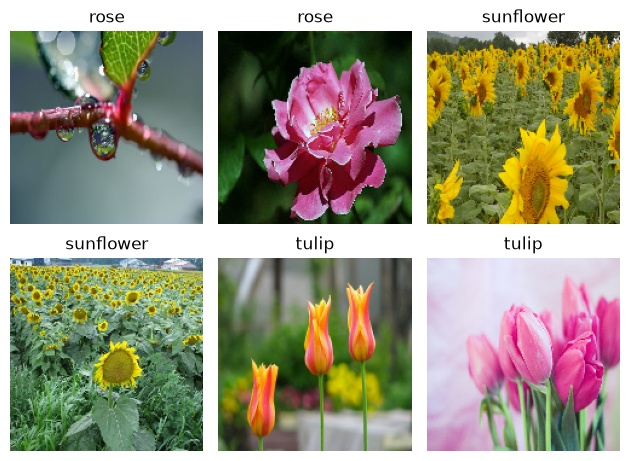

In [3]:
# Display some sample images from the training dataset

images, labels = next(iter(train_ds))

plot_idx = 1
for class_name in class_names:
    class_id = train_ds.class_names.index(class_name)
    indices = np.where(labels.numpy() == class_id)[0]

    for idx in indices[:2]:
        plt.subplot(2, len(class_names), plot_idx)
        plt.imshow(images[idx].numpy().astype("uint8"))
        plt.title(class_name)
        plt.axis("off")
        plot_idx += 1

plt.tight_layout()
plt.show()

Some images put the focus on other elements, too, like people, animals, which will probably make training on these images harder.

# Loading the Base Model

In [4]:
# Defining our results dictionary

results = {}

In [5]:
# Defining helper functions for compiling, fitting, plotting models and clearing the keras session

def compile_and_fit(model, epochs, learning_rate=1e-3, initial_epoch=0, callbacks=None):
    """Compile a classifier with Adam and train it on the bean images; return the learning curves."""
    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        metrics=["accuracy"],
    )
    history = model.fit(
        train_ds, validation_data=valid_ds, epochs=epochs, initial_epoch=initial_epoch, verbose=0, callbacks=callbacks
    )
    return pd.DataFrame(history.history, index=history.epoch)


def plot_curves(logs, title):
    """Plot the training and validation loss and accuracy of one run."""
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
    logs[["loss", "val_loss"]].plot(ax=ax_loss, xlabel="Epoch", title=f"{title}: loss")
    logs[["accuracy", "val_accuracy"]].plot(ax=ax_acc, xlabel="Epoch", title=f"{title}: accuracy")
    plt.show()

def clear_keras_session(base):
    """Clear the Keras session and set the random seed for reproducibility."""
    keras.utils.clear_session()
    keras.utils.set_random_seed(42)
    base.trainable = False

results = {}

In [6]:
# Instantiate the base model

base = mobilenet_v2.MobileNetV2(
    include_top=False, weights="imagenet", input_shape=IMAGE_SIZE + (3,), pooling="avg"
)

print(f"Convolutional base: {base.count_params():,} parameters, output shape {base.output.shape}")

Convolutional base: 2,257,984 parameters, output shape (None, 1280)


In [7]:
# Freeze the base model to prevent its weights from being updated during training

print(f"Before freezing: {len(base.trainable_weights)} trainable and {len(base.non_trainable_weights)} non-trainable weight tensors")
base.trainable = False
print(f"After freezing:  {len(base.trainable_weights)} trainable and {len(base.non_trainable_weights)} non-trainable weight tensors")

Before freezing: 156 trainable and 104 non-trainable weight tensors
After freezing:  0 trainable and 260 non-trainable weight tensors


# Extract Features from the Flower Images with the Base Model

In [8]:
# Extract features from the datasets using the frozen base model

def extract_features(dataset):
    """Run the frozen base over every batch of a dataset; return the feature vectors and the labels."""
    all_features = []
    all_labels = []
    for images, labels in dataset:  # one batch of up to 32 images at a time
        images = mobilenet_v2.preprocess_input(images)  # scale the pixels from 0 to 255 to -1 to 1
        features = base.predict(images, verbose=0)  # one row of 1,280 numbers per image
        all_features.append(features)
        all_labels.append(labels.numpy())
    return np.concatenate(all_features), np.concatenate(all_labels)  # stack the batches into one table



X_train, y_train = extract_features(load_images("train", shuffle=False))
X_valid, y_valid = extract_features(valid_ds)

print("Training features:", X_train.shape, " validation features:", X_valid.shape)

Found 300 files belonging to 3 classes.
Training features: (300, 1280)  validation features: (60, 1280)


# Train a Simple Head with Dropout and Softmax on the Extracted Features 

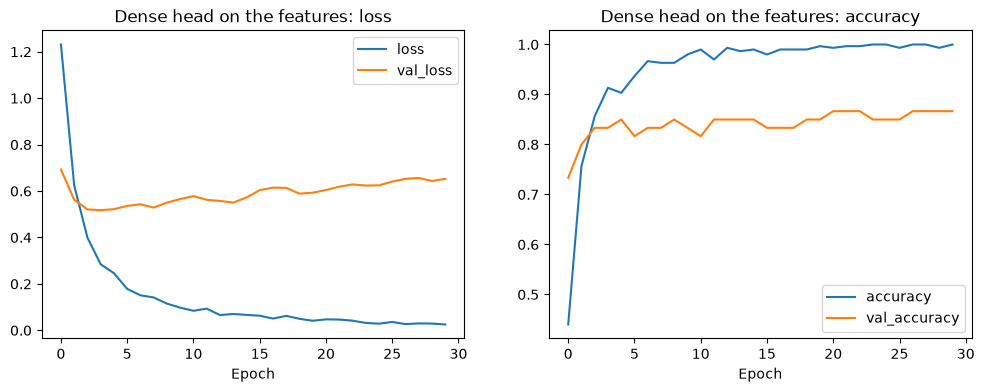

Validation accuracy: 86.667%
52 correct pictures of 60


In [9]:
clear_keras_session(base)

head = keras.Sequential(
    [
        keras.Input(shape=(X_train.shape[1],)),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(units=3, activation="softmax"),
    ]
)

head.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Adam(1e-3), metrics=["accuracy"])

head_history = head.fit(X_train, y_train, validation_data=(X_valid, y_valid), epochs=30, verbose=0)

plot_curves(pd.DataFrame(head_history.history), "Dense head on the features")

results["Frozen-Base-Features-Dropout"] = head.evaluate(X_valid, y_valid, verbose=0)[1]

print(f"Validation accuracy: {results['Frozen-Base-Features-Dropout']:.3%}")
print(f"{int(results['Frozen-Base-Features-Dropout'] * len(y_valid))} correct pictures of {len(y_valid)}")

# Data Augmentation

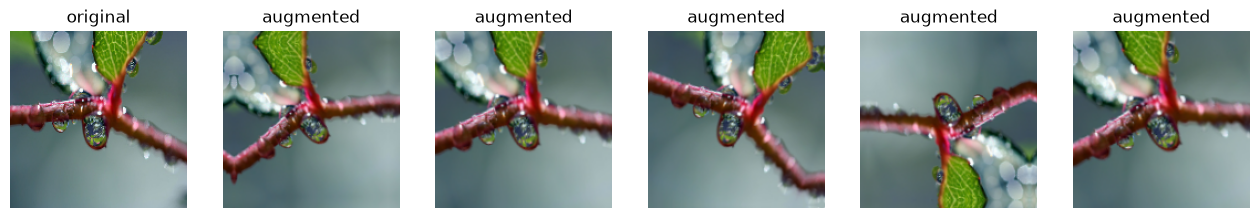

In [10]:
# Augment data

augmentation = keras.Sequential(
    [
        keras.layers.RandomFlip("horizontal_and_vertical"),
        keras.layers.RandomRotation(0.15),  
        keras.layers.RandomZoom(0.15),
    ],
    name="augmentation",
)

leaf = images[:1]  # one image from the first training batch
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(leaf[0].numpy().astype("uint8"))
axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(augmentation(leaf, training=True)[0].numpy().astype("uint8"))
    ax.set_title("augmented")
for ax in axes:
    ax.axis("off")

plt.show()

# Train the Same Head with Augmented Data

/Users/albert/projects/amle/flower-detection/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


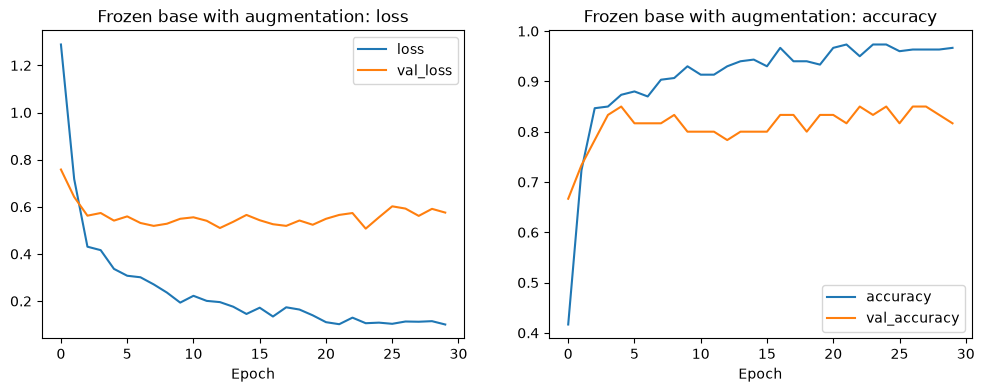

Validation accuracy: 81.667%
48 correct pictures of 60


In [11]:
# Train head model with augmented data

clear_keras_session(base)

augmented_model = keras.Sequential(
    [
        keras.Input(shape=IMAGE_SIZE + (3,)),
        augmentation,
        keras.layers.Rescaling(scale=1 / 127.5, offset=-1),  # the scaling of mobilenet_v2.preprocess_input
        base,  # the frozen convolutional base
        keras.layers.Dropout(0.2),
        keras.layers.Dense(units=3, activation="softmax"),
    ]
)

transfer_logs = compile_and_fit(augmented_model, epochs=30)
plot_curves(transfer_logs, "Frozen base with augmentation")
results["Frozen-Base-Augmented-Data"] = augmented_model.evaluate(valid_ds, verbose=0)[1]
print(f"Validation accuracy: {results['Frozen-Base-Augmented-Data']:.3%}")
print(f"{int(results['Frozen-Base-Augmented-Data'] * len(y_valid))} correct pictures of {len(y_valid)}")
    

## Result from Data Augmentation

The same head with augmented data performs worse on the validation set. 

81.7% accuracy on the validation set compared to 86.7% from the same head without data augmentation.

A difference of 5% accuracy.

# Model Tuning

In [12]:
# Definition of helper functions to create a tunable head for the model

def build_head(units, dropout_rate, learning_rate):
    """Return a compiled head for the 1,280 features: one hidden layer, dropout and a softmax output."""
    model = keras.Sequential(
        [
            keras.Input(shape=(X_train.shape[1],)),
            keras.layers.Dense(units=units, activation="relu"),
            keras.layers.Dropout(dropout_rate),
            keras.layers.Dense(units=3, activation="softmax"),
        ]
    )
    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        metrics=["accuracy"],
    )
    return model


def early_stopping():
    return keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True)

In [13]:
# Definition of a tunable head for the model using Keras Tuner

def build_tunable_head(hp):
    """Return a head whose hyperparameters are chosen by the tuner."""
    return build_head(
        units=hp.Int("units", min_value=32, max_value=256, step=32),
        dropout_rate=hp.Float("dropout_rate", min_value=0.0, max_value=0.5, step=0.1),
        learning_rate=hp.Choice("learning_rate", values=[1e-2, 1e-3, 1e-4]), # 0.01, 0.001, 0.0001
    )

In [14]:
tuner = kt.Hyperband(
    build_tunable_head,
    objective="val_accuracy",
    max_epochs=50,
    factor=3,
    seed=SEED,
    directory="./tuner",
    project_name="flowers_hyperband",
    overwrite=True
)

tuner.search_space_summary()

tuner.search(X_train, y_train, validation_data=(X_valid, y_valid), epochs=50, callbacks=[early_stopping()], verbose=0)

Search space summary
Default search space size: 3
units (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 256, 'step': 32, 'sampling': 'linear'}
dropout_rate (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


/Users/albert/projects/amle/flower-detection/.venv/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


In [15]:
trials = [{**trial.hyperparameters.values, "val_accuracy": trial.score} for trial in tuner.oracle.get_best_trials(15)]
pd.DataFrame(trials).round(4)

,units,dropout_rate,learning_rate,tuner/epochs,tuner/initial_epoch,tuner/bracket,tuner/round,tuner/trial_id,val_accuracy
0,32,0.3,0.010,17,6,2,1,0061,0.8833
1,256,0.1,0.001,2,0,3,0,NaN,0.8667
2,96,0.4,0.001,6,2,3,1,0001,0.8667
3,96,0.4,0.001,17,6,3,2,0038,0.8667
4,224,0.0,0.010,17,6,3,2,0040,0.8667
5,96,0.4,0.001,50,17,3,3,0046,0.8667
6,224,0.0,0.010,50,17,3,3,0048,0.8667
7,64,0.2,0.001,6,0,2,0,NaN,0.8667
8,32,0.3,0.010,6,0,2,0,NaN,0.8667
9,192,0.3,0.010,6,0,2,0,NaN,0.8667


Best hyperparameters: {'units': 32, 'dropout_rate': 0.30000000000000004, 'learning_rate': 0.01, 'tuner/epochs': 17, 'tuner/initial_epoch': 6, 'tuner/bracket': 2, 'tuner/round': 1, 'tuner/trial_id': '0061'}


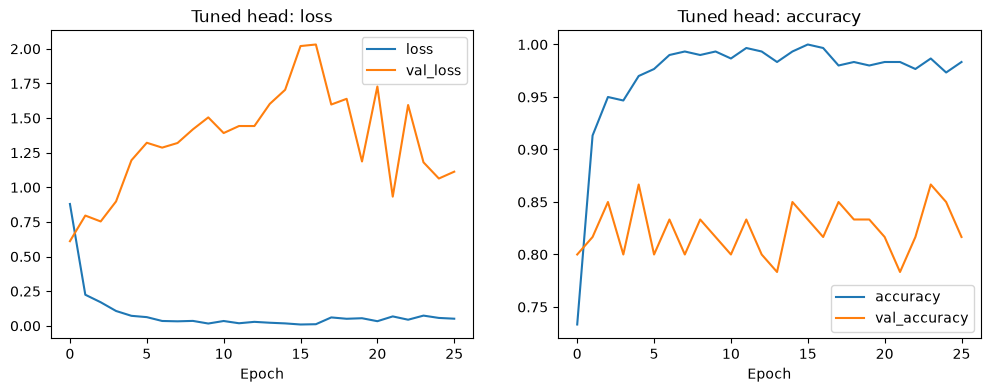

Validation accuracy: 80.000%
48 correct pictures of 60


In [16]:
best_hyperparameters = tuner.get_best_hyperparameters(1)[0]
print("Best hyperparameters:", best_hyperparameters.values)

clear_keras_session(base)

tuned_head = tuner.hypermodel.build(best_hyperparameters)

tuned_head_logs = tuned_head.fit(X_train, y_train, validation_data=(X_valid, y_valid), epochs=30, callbacks=[early_stopping()], verbose=0)

best_accuracy = tuned_head.evaluate(X_valid, y_valid, verbose=0)[1]

tuned_head_df = pd.DataFrame(tuned_head_logs.history, index=tuned_head_logs.epoch)

plot_curves(tuned_head_df, "Tuned head")

results["Frozen-Base-Tuned-Head"] = tuned_head.evaluate(X_valid, y_valid, verbose=0)[1]
print(f"Validation accuracy: {results['Frozen-Base-Tuned-Head']:.3%}")
print(f"{int(results['Frozen-Base-Tuned-Head'] * len(y_valid))} correct pictures of {len(y_valid)}")

## Result from the Tuned Model with One Dense Layer

The model tuned on the hyperparameters one dense layer with 256 units, a dropout rate of 0.3 and a learning rate of 0.01 achieved 85% accuracy on the validation set.

It predicted 51 of 60 flowers correctly.

This is a worse performance compared to the untuned head with a validation accuracy of 86.7% but in the range of variation.

# Model Tuning with Variable Number of Layers 

In [17]:
def build_deeper_head(hp):
    """Return a head with 1 or 2 hidden layers chosen by the tuner."""
    layers = [keras.Input(shape=(X_train.shape[1],))]

    n_layers = hp.Int("n_layers", min_value=1, max_value=3, step=1)
    for i in range(n_layers):
        layers.append(keras.layers.Dense(units=hp.Int(f"units_{i}", 32, 256, step=32), activation="relu"))
        layers.append(keras.layers.Dropout(hp.Float("dropout_rate", 0.0, 0.5, step=0.1)))
    layers.append(keras.layers.Dense(units=3, activation="softmax"))
    model = keras.Sequential(layers)
    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=keras.optimizers.Adam(learning_rate=hp.Choice("learning_rate", values=[1e-2, 1e-3, 1e-4])),
        metrics=["accuracy"],
    )
    return model

deeper_tuner =  kt.Hyperband(
    build_deeper_head,
    objective="val_accuracy",
    max_epochs=50,
    factor=3,
    seed=SEED,
    directory="./tuner",
    project_name="flowers_deeper_hyperband",
    overwrite=True
)

In [18]:

deeper_tuner.search(X_train, y_train, validation_data=(X_valid, y_valid), epochs=50, callbacks=[early_stopping()], verbose=0)
deeper_hp = deeper_tuner.get_best_hyperparameters(1)[0]
print("Best hyperparameters:", deeper_hp.values)

/Users/albert/projects/amle/flower-detection/.venv/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)
/Users/albert/projects/amle/flower-detection/.venv/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)
/Users/albert/projects/amle/flower-detection/.venv/lib/python3.13/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(store)


Best hyperparameters: {'n_layers': 3, 'units_0': 160, 'dropout_rate': 0.30000000000000004, 'learning_rate': 0.001, 'units_1': 64, 'units_2': 96, 'tuner/epochs': 50, 'tuner/initial_epoch': 17, 'tuner/bracket': 3, 'tuner/round': 3, 'tuner/trial_id': '0049'}


In [19]:
deeper_trials = [{**trial.hyperparameters.values, "val_accuracy": trial.score} for trial in deeper_tuner.oracle.get_best_trials(15)]
pd.DataFrame(deeper_trials).round(4)

,n_layers,units_0,dropout_rate,learning_rate,units_1,units_2,tuner/epochs,tuner/initial_epoch,tuner/bracket,tuner/round,tuner/trial_id,val_accuracy
0,3,160,0.3,0.001,64,96,50,17,3,3,0049,0.8667
1,2,224,0.2,0.010,224,32,6,0,2,0,NaN,0.8667
2,2,96,0.3,0.001,224,256,17,6,2,1,0055,0.8667
3,2,96,0.3,0.001,224,256,50,17,2,2,0068,0.8667
4,2,224,0.2,0.010,224,32,50,17,2,2,0067,0.8667
5,3,32,0.1,0.010,32,96,17,0,1,0,NaN,0.8667
6,1,192,0.1,0.010,32,256,17,0,1,0,NaN,0.8667
7,3,32,0.1,0.010,32,96,50,17,1,1,0080,0.8667
8,2,224,0.3,0.001,128,160,50,0,0,0,NaN,0.8667
9,2,256,0.1,0.010,32,256,50,0,0,0,NaN,0.8667


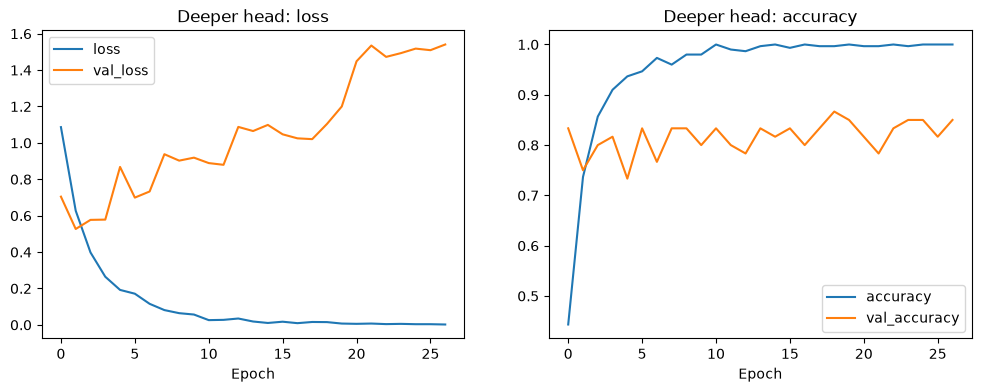

Test accuracy: 100.000%
Validation accuracy: 75.000%
45 correct pictures of 60


In [20]:

clear_keras_session(base)

deeper_head = deeper_tuner.hypermodel.build(deeper_hp)
deeper_head_logs = deeper_head.fit(X_train, y_train, validation_data=(X_valid, y_valid), epochs=50, callbacks=[early_stopping()], verbose=0)

best_accuracy = deeper_head.evaluate(X_valid, y_valid, verbose=0)[1]

deeper_head_df = pd.DataFrame(deeper_head_logs.history, index=deeper_head_logs.epoch)

plot_curves(deeper_head_df, "Deeper head")

results["Frozen-Base-Deeper-Head"] = deeper_head.evaluate(X_valid, y_valid, verbose=0)[1]
print(f"Test accuracy: {deeper_head_logs.history['accuracy'][-1]:.3%}")
print(f"Validation accuracy: {results['Frozen-Base-Deeper-Head']:.3%}")
print(f"{int(results['Frozen-Base-Deeper-Head'] * len(y_valid))} correct pictures of {len(y_valid)}")

## Results from the Deeper Tuned Head

The Tuned Head with three layers performs worse on the validation set compared to all other models with a validation accuracy of 78.3%.

It is clearly overfitting with a test accuracy of 100%.

# Save the Models to a File

In [21]:
Path("models").mkdir(exist_ok=True)

head.save('models/frozen_base_features_dropout.keras')

augmented_model.save('models/frozen_base_augmented_data.keras')

tuned_head.save('models/frozen_base_tuned_head.keras')

deeper_head.save('models/frozen_base_deeper_head.keras')

In [22]:
# Display the validation accuracy results for all models so far

pd.DataFrame(results, index=["Validation Accuracy"]).T.round(4)


,Validation Accuracy
Frozen-Base-Features-Dropout,0.8667
Frozen-Base-Augmented-Data,0.8167
Frozen-Base-Tuned-Head,0.8000
Frozen-Base-Deeper-Head,0.7500


# Model Fine-Tuning

## Model Fine-Tuning with Data Augmentation and a Simple Head

Trainable layers in the base: 20 of 155


/Users/albert/projects/amle/flower-detection/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


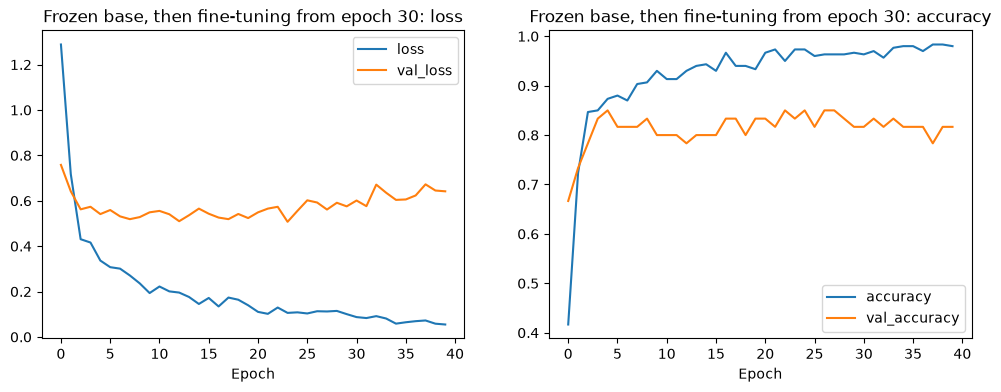

In [ ]:
# Fine-tuning the last layers of the base model

base.trainable = True

for layer in base.layers[:-30]:  # keep everything except the last 30 layers frozen
    layer.trainable = False
for layer in base.layers:  # batch normalisation layers stay frozen
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
print(f"Trainable layers in the base: {sum(layer.trainable for layer in base.layers)} of {len(base.layers)}")


# Compile and fine-tune the model with the head from the data augmentation 
fine_logs = compile_and_fit(augmented_model, epochs=40, learning_rate=1e-5, initial_epoch=30)
plot_curves(pd.concat([transfer_logs, fine_logs]), "Frozen base, then fine-tuning from epoch 30")

# save the model
augmented_model.save('models/fine_tuned_data_augmented.keras')


In [24]:
results["Fine-Tuned-Data-Augmented"] = augmented_model.evaluate(valid_ds, verbose=0)[1]
print(f"Validation accuracy: {results['Fine-Tuned-Data-Augmented']:.3%}")

Validation accuracy: 81.667%


## Model Fine-Tuning WITHOUT Data Augmentation

Trainable layers in the base: 20 of 155


/Users/albert/projects/amle/flower-detection/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


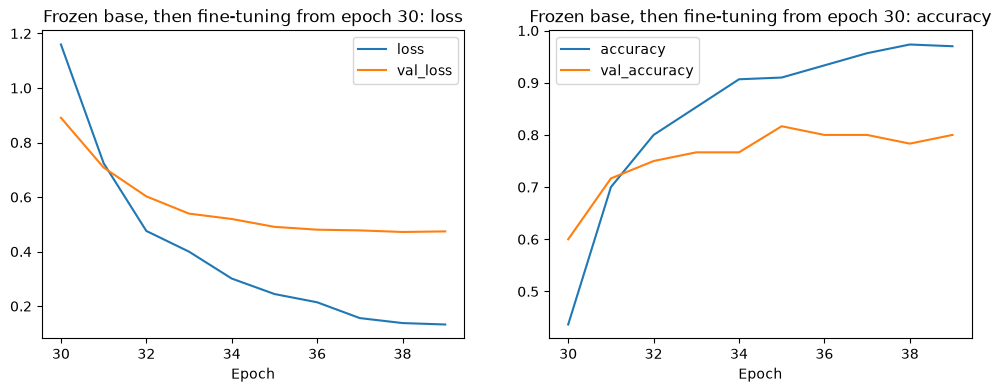

Validation accuracy: 81.667%


In [34]:
# Fine-tuning the last layers of the base model without data augmentation
keras.utils.clear_session()
keras.utils.set_random_seed(42)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=10, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("models/fine_tuned_simple_head.keras", monitor="val_accuracy", save_best_only=True)
    ]

fresh_base = mobilenet_v2.MobileNetV2(
    include_top=False, weights="imagenet", input_shape=IMAGE_SIZE + (3,), pooling="avg"
)

simple_head = keras.Sequential(
    [
        keras.Input(shape=IMAGE_SIZE + (3,)),
        keras.layers.Rescaling(scale=1 / 127.5, offset=-1),  # the scaling of mobilenet_v2.preprocess_input
        fresh_base,  # the frozen convolutional base
        keras.layers.Dropout(0.2),
        keras.layers.Dense(units=3, activation="softmax"),
    ]
)

fresh_base.trainable = True

for layer in fresh_base.layers[:-30]:  # keep everything except the last 30 layers frozen
    layer.trainable = False
for layer in fresh_base.layers:  # batch normalisation layers stay frozen
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
print(f"Trainable layers in the base: {sum(layer.trainable for layer in fresh_base.layers)} of {len(fresh_base.layers)}")

# Compile and fine-tune the model with the head from the data augmentation 
fine_logs_simple_head = compile_and_fit(simple_head, epochs=40, learning_rate=1e-5, initial_epoch=30, callbacks=callbacks)

plot_curves(fine_logs_simple_head, "Frozen base, then fine-tuning from epoch 30")

fine_tuned_simple_head = keras.saving.load_model('models/fine_tuned_simple_head.keras')

results["Fine-Tuned-Simple-Head"] = fine_tuned_simple_head.evaluate(valid_ds, verbose=0)[1]

print(f"Validation accuracy: {results['Fine-Tuned-Simple-Head']:.3%}")

## Results from Fine-Tuning

Both fine-tuned models with and without augmented data did not yield a performance improvement.

Both landed at 81.7% validation accuracy.

The second fine-tuned model without data augmentation performed significantly better and landed at 85% validation accuracy after 40 epochs,
while the accuracy was still improving.

In [47]:
# Save results dict to file
import json

results["Fine-Tuned-Augmented-Data"] = results["Fine-Tuned-Data-Augmented"]

with open("results.json", "w") as f:
    json.dump(results, f)

# Evaluate Models on the Test Data

See other jupyter notebook.